# Football Agent


# Setup


In [1]:
import os
import json
import csv
import time
from pathlib import Path
from datetime import date
from typing import Annotated, TypedDict, Literal, Optional, Any, Iterable
import re

from dotenv import load_dotenv
load_dotenv()

if not os.environ.get("GROQ_API_KEY"):
    raise RuntimeError("Set GROQ_API_KEY in your .env file")

MAIN_MODEL = "groq:openai/gpt-oss-20b"
STRONG_MODEL = "groq:openai/gpt-oss-120b"

from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
from langchain.tools import tool
from langchain_core.messages import (
    AIMessage, HumanMessage, SystemMessage, BaseMessage, ToolMessage,
)

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

print("Ready. Main model:", MAIN_MODEL)

Ready. Main model: groq:openai/gpt-oss-20b


# Model Connectivity Check


In [2]:
import os
import groq

client = groq.Groq(api_key=os.environ["GROQ_API_KEY"])

for m in client.models.list().data:
    print(m.id)

whisper-large-v3
allam-2-7b
openai/gpt-oss-120b
openai/gpt-oss-safeguard-20b
qwen/qwen3.8-27b
whisper-large-v3-turbo
canopylabs/orpheus-arabic-saudi
openai/gpt-oss-20b
meta-llama/llama-prompt-guard-2-86m
meta-llama/llama-prompt-guard-2-22m
canopylabs/orpheus-v1-english


# Data Loading and Validation


In [3]:
# ============ Real Premier League 2024/25 Dataset ============

DATA_DIR = Path("Data")
TABLE_CSV = DATA_DIR / "Table.csv"
PLAYER_CSV = DATA_DIR / "Player_Stats.csv"
MATCHES_JSONL = DATA_DIR / "match_reports.jsonl"

for p in (TABLE_CSV, PLAYER_CSV, MATCHES_JSONL):
    if not p.exists():
        raise FileNotFoundError(f"Missing dataset file: {p.resolve()}")


def _load_table() -> list[dict[str, Any]]:
    with TABLE_CSV.open(newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))


def _load_players() -> list[dict[str, Any]]:
    with PLAYER_CSV.open(newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))


def _load_matches() -> list[dict[str, Any]]:
    records = []
    with MATCHES_JSONL.open(encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            rec = json.loads(line)
            # Each record is {"id":..., "match_report": {...}}
            mr = rec.get("match_report", rec)
            records.append(mr)
    return records


def validate_datasets(table_rows, player_rows, match_reports):
    required_table = {"Rk", "Squad", "MP", "Pts"}
    required_player = {"Player", "Squad", "Playing Time_Min", "Playing Time_MP",
                       "Performance_Gls", "Performance_Ast", "Per 90 Minutes_Gls",
                       "Per 90 Minutes_Ast", "Per 90 Minutes_G+A"}
    if not table_rows or not player_rows or not match_reports:
        raise ValueError("A required dataset is empty")
    missing_table = required_table - set(table_rows[0])
    missing_player = required_player - set(player_rows[0])
    if missing_table or missing_player:
        raise ValueError(f"Missing dataset columns: table={missing_table}, players={missing_player}")
    parsed_dates = []
    for report in match_reports:
        match_date = date.fromisoformat(report["date"])
        teams = report["teams"]
        for side in ("home", "away"):
            if not teams[side].get("name") or teams[side].get("score") is None:
                raise ValueError(f"Incomplete match record on {match_date}")
        parsed_dates.append(match_date)
    return {"table_rows": len(table_rows), "player_rows": len(player_rows),
            "match_reports": len(match_reports), "match_start": min(parsed_dates).isoformat(),
            "match_end": max(parsed_dates).isoformat()}


# Load once at import time (small files, fine to cache in memory)
TABLE_ROWS = _load_table()
PLAYER_ROWS = _load_players()
MATCH_REPORTS = _load_matches()
DATA_VALIDATION = validate_datasets(TABLE_ROWS, PLAYER_ROWS, MATCH_REPORTS)
print(f"Validated datasets: {DATA_VALIDATION}")

Validated datasets: {'table_rows': 20, 'player_rows': 574, 'match_reports': 158, 'match_start': '2024-08-18', 'match_end': '2024-12-22'}


# Existing Architecture


# Tools and Helpers


In [4]:
# ============ Dataset Tools (deterministic, from real files) ============

# Player comparison implementation

PER_90_COLUMNS = {
    "goals": "Per 90 Minutes_Gls",
    "assists": "Per 90 Minutes_Ast",
    "goals_assists": "Per 90 Minutes_G+A",
    "non_penalty_goals": "Per 90 Minutes_G-PK",
    "non_penalty_goals_assists": "Per 90 Minutes_G+A-PK",
}


def _number(value: Any, *, integer: bool = False) -> int | float | None:
    if value is None or str(value).strip() == "":
        return None
    try:
        number = float(value)
    except (TypeError, ValueError):
        return None
    return int(number) if integer else number


def _resolve_player(
    rows: Iterable[dict[str, Any]], player_name: str, team: str | None
) -> tuple[str, dict[str, Any] | None, list[dict[str, str]]]:
    """Resolve a name only when it identifies one row; return safe choices otherwise."""
    query = (player_name or "").strip().casefold()
    team_query = (team or "").strip().casefold()
    all_rows = list(rows)
    exact = [r for r in all_rows if str(r.get("Player", "")).strip().casefold() == query]
    candidates = exact or [
        r for r in all_rows if query and query in str(r.get("Player", "")).casefold()
    ]
    if team_query:
        candidates = [
            r for r in candidates
            if str(r.get("Squad", "")).strip().casefold() == team_query
        ]
    choices = [
        {"player": str(r.get("Player", "")), "team": str(r.get("Squad", ""))}
        for r in candidates
    ]
    if not candidates:
        return "missing", None, []
    if len(candidates) > 1:
        # Collapse byte-for-byte duplicate rows only if all requested stat fields agree.
        unique: dict[tuple[Any, ...], dict[str, Any]] = {}
        keys = ("Player", "Squad", "Playing Time_Min", "Playing Time_MP",
                "Performance_Gls", "Performance_Ast", *PER_90_COLUMNS.values())
        for row in candidates:
            unique.setdefault(tuple(row.get(k) for k in keys), row)
        candidates = list(unique.values())
        choices = [
            {"player": str(r.get("Player", "")), "team": str(r.get("Squad", ""))}
            for r in candidates
        ]
    if len(candidates) != 1:
        return "ambiguous", None, choices
    return "ok", candidates[0], choices


def _player_values(row: dict[str, Any]) -> dict[str, Any]:
    minutes = _number(row.get("Playing Time_Min"), integer=True)
    values: dict[str, Any] = {
        "player": row.get("Player"),
        "team": row.get("Squad"),
        "goals": _number(row.get("Performance_Gls"), integer=True),
        "assists": _number(row.get("Performance_Ast"), integer=True),
        "minutes": minutes,
        "appearances": _number(row.get("Playing Time_MP"), integer=True),
    }
    per_90: dict[str, float | None] = {}
    for label, column in PER_90_COLUMNS.items():
        # A per-90 rate is not meaningful when the source row records no minutes.
        per_90[label] = None if minutes in (None, 0) else _number(row.get(column))
    values["per_90"] = per_90
    return values


def compare_players(
    rows: Iterable[dict[str, Any]],
    player_a: str,
    player_b: str,
    team_a: str | None = None,
    team_b: str | None = None,
) -> dict[str, Any]:
    """Compare two identified player rows using only values present in the CSV."""
    status_a, row_a, choices_a = _resolve_player(rows, player_a, team_a)
    status_b, row_b, choices_b = _resolve_player(rows, player_b, team_b)
    unresolved = []
    if status_a != "ok":
        unresolved.append({"requested": player_a, "team": team_a, "status": status_a,
                           "candidates": choices_a})
    if status_b != "ok":
        unresolved.append({"requested": player_b, "team": team_b, "status": status_b,
                           "candidates": choices_b})
    if unresolved:
        return {"status": "clarification_required", "players": unresolved}

    a, b = _player_values(row_a), _player_values(row_b)
    if row_a is row_b:
        return {"status": "clarification_required", "reason":
                "The same player row was selected twice; identify two different players."}
    comparable = ("goals", "assists", "minutes", "appearances")
    differences = {
        field: (a[field] - b[field])
        if a[field] is not None and b[field] is not None else None
        for field in comparable
    }
    differences["per_90"] = {
        key: round(a["per_90"][key] - b["per_90"][key], 2)
        if a["per_90"][key] is not None and b["per_90"][key] is not None else None
        for key in PER_90_COLUMNS
    }
    return {
        "status": "ok",
        "players": [a, b],
        "difference_player_a_minus_player_b": differences,
        "difference_order": [a["player"], b["player"]],
    }


# Team form and head-to-head implementation

ALIASES = {
    "wolves": "Wolverhampton Wanderers",
    "man city": "Manchester City",
    "man utd": "Manchester United",
    "man united": "Manchester United",
    "spurs": "Tottenham Hotspur",
}

PERIOD_NOTE = (
    "Repository coverage is partial for the 2024/25 season; these are only the "
    "matches present in the available reports, which end on 2024-12-22. "
    "They are not current real-world results."
)
H2H_NOTE = (
    "Head-to-head history is incomplete: this includes only meetings present in "
    "the repository's partial 2024/25 match reports, ending on 2024-12-22. "
    "It does not establish the complete earlier or later history between these teams."
)


def _score(value: Any) -> int | None:
    if value is None or str(value).strip() == "":
        return None
    try:
        number = float(value)
        return int(number) if number.is_integer() and number >= 0 else None
    except (TypeError, ValueError):
        return None


def _team_name(team_data: dict[str, Any]) -> str | None:
    name = team_data.get("name") or team_data.get("team") or team_data.get("title")
    return str(name).strip() if name else None


def _normalise_matches(match_reports: Iterable[dict[str, Any]]) -> list[dict[str, Any]]:
    matches = []
    for report in match_reports:
        teams = report.get("teams") or {}
        home, away = teams.get("home") or {}, teams.get("away") or {}
        home_name, away_name = _team_name(home), _team_name(away)
        home_score = _score(home.get("score", report.get("home_score")))
        away_score = _score(away.get("score", report.get("away_score")))
        raw_date = report.get("date")
        try:
            match_date = date.fromisoformat(str(raw_date))
        except (TypeError, ValueError):
            continue
        if not home_name or not away_name or home_score is None or away_score is None:
            continue
        matches.append({
            "date": match_date.isoformat(),
            "_date": match_date,
            "home_team": home_name,
            "away_team": away_name,
            "home_score": home_score,
            "away_score": away_score,
            "venue": report.get("venue"),
        })
    return matches


def _resolve_team(query: str, matches: list[dict[str, Any]]) -> dict[str, Any]:
    known = sorted({m[side] for m in matches for side in ("home_team", "away_team")})
    value = (query or "").strip().casefold()
    alias = ALIASES.get(value)
    if alias:
        exact_alias = [name for name in known if name.casefold() == alias.casefold()]
        if exact_alias:
            return {"status": "ok", "team": exact_alias[0]}
    exact = [name for name in known if name.casefold() == value]
    candidates = exact or [name for name in known if value and value in name.casefold()]
    if len(candidates) == 1:
        return {"status": "ok", "team": candidates[0]}
    return {"status": "clarification_required",
            "reason": "ambiguous" if candidates else "missing",
            "requested": query, "candidates": candidates}


def _coverage(matches: list[dict[str, Any]]) -> dict[str, Any]:
    dates = [m["date"] for m in matches]
    return {
        "data_period": {"start": min(dates) if dates else None,
                        "end": max(dates) if dates else None},
        "coverage_note": PERIOD_NOTE,
    }


def _outcome(goals_for: int, goals_against: int) -> str:
    return "W" if goals_for > goals_against else "D" if goals_for == goals_against else "L"


def _summarize(team: str, matches: list[dict[str, Any]]) -> dict[str, Any]:
    recent = [m for m in matches if team in (m["home_team"], m["away_team"])]
    recent.sort(key=lambda m: (m["_date"], m["home_team"], m["away_team"]), reverse=True)
    selected = recent[:5]
    results = []
    wins = draws = losses = gf = ga = points = 0
    for match in selected:
        is_home = match["home_team"] == team
        opponent = match["away_team"] if is_home else match["home_team"]
        goals_for = match["home_score"] if is_home else match["away_score"]
        goals_against = match["away_score"] if is_home else match["home_score"]
        result = _outcome(goals_for, goals_against)
        wins += result == "W"
        draws += result == "D"
        losses += result == "L"
        gf += goals_for
        ga += goals_against
        points += 3 if result == "W" else 1 if result == "D" else 0
        results.append({
            "date": match["date"],
            "opponent": opponent,
            "score": f"{goals_for}-{goals_against}",
            "goals_for": goals_for,
            "goals_against": goals_against,
            "venue_status": "home" if is_home else "away",
            "result": result,
        })
    return {
        "team": team,
        "matches_available": len(recent),
        "matches_in_form": len(selected),
        "most_recent_available_match_date": recent[0]["date"] if recent else None,
        "matches": results,
        "summary": {"wins": wins, "draws": draws, "losses": losses,
                    "goals_scored": gf, "goals_conceded": ga,
                    "goal_difference": gf - ga, "points": points},
    }


def team_form(match_reports: Iterable[dict[str, Any]], team_a: str,
              team_b: str | None = None) -> dict[str, Any]:
    """Return each requested team's latest five available matches and totals."""
    reports = list(match_reports)
    matches = _normalise_matches(reports)
    resolved_a = _resolve_team(team_a, matches)
    resolved_b = _resolve_team(team_b, matches) if team_b else None
    unresolved = [r for r in (resolved_a, resolved_b)
                  if r is not None and r["status"] != "ok"]
    result: dict[str, Any] = {"status": "clarification_required" if unresolved else "ok",
                              **_coverage(matches)}
    if unresolved:
        result["teams"] = unresolved
        return result
    result["teams"] = [_summarize(resolved_a["team"], matches)]
    if resolved_b:
        if resolved_a["team"] == resolved_b["team"]:
            return {"status": "clarification_required", "reason":
                    "The same team was resolved for both comparison inputs.",
                    **_coverage(matches)}
        result["teams"].append(_summarize(resolved_b["team"], matches))
    return result


def head_to_head(match_reports: Iterable[dict[str, Any]], team_a: str,
                 team_b: str) -> dict[str, Any]:
    """Return meetings and aggregate record from team_a's perspective."""
    matches = _normalise_matches(match_reports)
    resolved_a, resolved_b = _resolve_team(team_a, matches), _resolve_team(team_b, matches)
    unresolved = [r for r in (resolved_a, resolved_b) if r["status"] != "ok"]
    if unresolved:
        return {"status": "clarification_required", "teams": unresolved,
                **_coverage(matches)}
    first, second = resolved_a["team"], resolved_b["team"]
    if first == second:
        return {"status": "clarification_required", "reason":
                "The same team was resolved for both inputs.", **_coverage(matches)}
    meetings = [m for m in matches if {m["home_team"], m["away_team"]} == {first, second}]
    meetings.sort(key=lambda m: (m["_date"], m["home_team"], m["away_team"]))
    wins = draws = losses = gf = ga = 0
    output = []
    for m in meetings:
        is_home = m["home_team"] == first
        goals_for = m["home_score"] if is_home else m["away_score"]
        goals_against = m["away_score"] if is_home else m["home_score"]
        result = _outcome(goals_for, goals_against)
        wins += result == "W"
        draws += result == "D"
        losses += result == "L"
        gf += goals_for
        ga += goals_against
        output.append({"date": m["date"], "home_team": m["home_team"],
                       "away_team": m["away_team"], "score":
                       f"{m['home_score']}-{m['away_score']}",
                       "home_score": m["home_score"], "away_score": m["away_score"],
                       "venue": m["venue"], "result_for_first_team": result})
    return {
        "status": "ok", "team_a": first, "team_b": second,
        "matches": output,
        "summary_for_team_a": {"total_matches": len(meetings), "wins": wins,
                               "draws": draws, "losses": losses,
                               "goals_scored": gf, "goals_conceded": ga},
        "history_note": H2H_NOTE,
        **_coverage(matches),
    }


def query_match_analysis(match_reports: Iterable[dict[str, Any]], query: str) -> str | None:
    """Format deterministic answers for recognized form/H2H natural-language queries.

    The notebook still runs the LangGraph workflow first. This final formatter keeps
    its user-facing match facts and coverage metadata tied to the same deterministic
    functions, even if an LLM omits or embellishes tool output.
    """
    reports = list(match_reports)
    matches = _normalise_matches(reports)
    text = (query or "").casefold()
    h2h_intent = any(term in text for term in ("head-to-head", "head to head", "h2h"))
    if not h2h_intent and "how many times" in text and any(
        word in text for word in (" beat ", "beat ", " defeated", "defeat")
    ):
        h2h_intent = True
    form_intent = any(term in text for term in (
        "last five", "last 5", "recent form", "team form", "recent results",
    )) or ("form" in text and not h2h_intent)
    if not (h2h_intent or form_intent):
        return None

    known = sorted({m[side] for m in matches for side in ("home_team", "away_team")})
    phrases = [(name.casefold(), name) for name in known]
    phrases.extend((alias, canonical) for alias, canonical in ALIASES.items())
    found: list[str] = []
    mentions = [(text.find(phrase), -len(phrase), canonical)
                for phrase, canonical in phrases
                if phrase in text and canonical in known]
    for _, _, canonical in sorted(mentions):
        if canonical not in found:
            found.append(canonical)

    def clarification(message: str) -> str:
        return message + " Available team names: " + ", ".join(known) + "."

    if h2h_intent:
        if len(found) < 2:
            return clarification("Please identify both teams for the head-to-head comparison.")
        result = head_to_head(reports, found[0], found[1])
        if result["status"] != "ok":
            return clarification("I could not resolve both teams reliably.")
        summary = result["summary_for_team_a"]
        lines = [f"## Head-to-head: {result['team_a']} vs {result['team_b']}", ""]
        if result["matches"]:
            for m in result["matches"]:
                venue = f" — {m['venue']}" if m["venue"] else ""
                lines.append(
                    f"- {m['date']}: {m['home_team']} {m['score']} {m['away_team']}"
                    f"{venue} ({m['result_for_first_team']} for {result['team_a']})"
                )
        else:
            lines.append("- No meetings are present in the available reports.")
        lines.extend(["", f"Record for {result['team_a']}: {summary['total_matches']} matches; "
                      f"{summary['wins']} wins, {summary['draws']} draws, "
                      f"{summary['losses']} losses; {summary['goals_scored']} goals scored, "
                      f"{summary['goals_conceded']} conceded.",
                      f"Data period: {result['data_period']['start']} to "
                      f"{result['data_period']['end']}.", result["history_note"]])
        return "\n".join(lines)

    if not found:
        return clarification("Please identify the team whose form or results you want.")
    result = team_form(reports, found[0], found[1] if len(found) > 1 else None)
    if result["status"] != "ok":
        return clarification("I could not resolve the requested team names reliably.")
    lines = []
    for summary in result["teams"]:
        lines.extend([f"## {summary['team']} — latest five available matches", "",
                      f"Matches available in reports: {summary['matches_available']}. "
                      f"Most recent available match: "
                      f"{summary['most_recent_available_match_date'] or 'none'}."])
        if summary["matches"]:
            for m in summary["matches"]:
                lines.append(f"- {m['date']}: vs {m['opponent']} ({m['venue_status']}) "
                             f"{m['score']} — {m['result']}")
        else:
            lines.append("- No matches are present for this team in the available reports.")
        totals = summary["summary"]
        lines.extend([f"- Record: {totals['wins']} W, {totals['draws']} D, "
                      f"{totals['losses']} L; {totals['goals_scored']} goals for, "
                      f"{totals['goals_conceded']} against; goal difference "
                      f"{totals['goal_difference']:+}; {totals['points']} points.", ""])
    lines.extend([f"Data period: {result['data_period']['start']} to "
                  f"{result['data_period']['end']}.", result["coverage_note"]])
    return "\n".join(lines)


def _query_player_comparison(rows: Iterable[dict[str, Any]], query: str) -> str | None:
    """Format identified natural-language comparisons using deterministic values."""
    text = (query or "").casefold()
    if not re.search(r"\b(compare|comparison|versus|vs)\b", text):
        return None
    names = sorted({str(r.get("Player", "")).strip() for r in rows if r.get("Player")})
    mentions = []
    for name in names:
        match = re.search(r"(?<!\w)" + re.escape(name.casefold()) + r"(?!\w)", text)
        if match:
            mentions.append((match.start(), -len(name), name))
    if len({m[2] for m in mentions}) < 2:
        tokens = {m.group().casefold(): m.start() for m in re.finditer(r"[\w]+", text)}
        for name in names:
            surname = name.split()[-1].casefold()
            if len(surname) >= 4 and surname in tokens and name not in {x[2] for x in mentions}:
                mentions.append((tokens[surname], -len(name), name))
    ordered = []
    for _, _, name in sorted(mentions):
        if name not in ordered: ordered.append(name)
    if len(ordered) != 2: return None

    def team_qualifier(name):
        squads = {str(r.get("Squad", "")) for r in rows
                  if str(r.get("Player", "")).casefold() == name.casefold()}
        found = [s for s in squads if s and s.casefold() in text]
        if not found:
            found = [canonical for alias, canonical in ALIASES.items()
                     if alias in text and canonical in squads]
        return found[0] if len(found) == 1 else None

    result = compare_players(rows, ordered[0], ordered[1],
                             team_qualifier(ordered[0]), team_qualifier(ordered[1]))
    if result["status"] != "ok":
        lines = ["Please clarify the player comparison:"]
        for item in result.get("players", []):
            teams = ", ".join(c["team"] for c in item.get("candidates", []))
            lines.append(f"- {item['requested']}: {item['status']}" + (f" (teams: {teams})" if teams else ""))
        if result.get("reason"): lines.append(f"- {result['reason']}")
        return "\n".join(lines)

    a, b = result["players"]
    delta = result["difference_player_a_minus_player_b"]
    show = lambda value: "N/A" if value is None else str(value)
    lines = [f"## {a['player']} ({a['team']}) vs {b['player']} ({b['team']})", "",
             "| Statistic | Player A | Player B | A - B |", "|---|---:|---:|---:|"]
    for key, label in (("goals", "Goals"), ("assists", "Assists"),
                       ("minutes", "Minutes"), ("appearances", "Appearances")):
        lines.append(f"| {label} | {show(a[key])} | {show(b[key])} | {show(delta[key])} |")
    for key, label in (("goals", "Goals per 90"), ("assists", "Assists per 90"),
        ("goals_assists", "G+A per 90 (Per 90 Minutes_G+A)"),
        ("non_penalty_goals", "Non-penalty goals per 90"),
        ("non_penalty_goals_assists", "Non-penalty G+A per 90 (Per 90 Minutes_G+A-PK)")):
        lines.append(f"| {label} | {show(a['per_90'][key])} | {show(b['per_90'][key])} | {show(delta['per_90'][key])} |")
    return "\n".join(lines)



def _to_int(v, default=0):
    try:
        return int(float(v))
    except (TypeError, ValueError):
        return default


def _to_float(v, default=0.0):
    try:
        return float(v)
    except (TypeError, ValueError):
        return default


@tool
def get_league_table(top_n: Optional[int] = None) -> str:
    """
    Return the project-default Premier League 2024/25 league table.
    If top_n is given, return only the top N rows (e.g. top_n=4 for the top 4).
    Use all rows for team goals scored or conceded and best attack/defense comparisons.
    """
    rows = sorted(TABLE_ROWS, key=lambda r: _to_int(r.get("Rk"), 999))
    if top_n:
        rows = rows[: int(top_n)]
    out = [{
        "position":       _to_int(r.get("Rk")),
        "team":           r.get("Squad"),
        "played":         _to_int(r.get("MP")),
        "wins":           _to_int(r.get("W")),
        "draws":          _to_int(r.get("D")),
        "losses":         _to_int(r.get("L")),
        "goals_for":      _to_int(r.get("GF")),
        "goals_against":  _to_int(r.get("GA")),
        "goal_diff":      _to_int(r.get("GD")),
        "points":         _to_int(r.get("Pts")),
        "points_per_match": _to_float(r.get("Pts/MP")),
        "xG":             _to_float(r.get("xG")),
        "xGA":            _to_float(r.get("xGA")),
        "xGD":            _to_float(r.get("xGD")),
        "xGD_per_90":     _to_float(r.get("xGD/90")),
        "top_team_scorer": r.get("Top Team Scorer"),
        "goalkeeper":     r.get("Goalkeeper"),
        "notes":          r.get("Notes"),
    } for r in rows]
    return json.dumps(out, ensure_ascii=False)




def query_team_table_leader(table_rows, query):
    text = (query or "").casefold()
    if not any(term in text for term in ("team", "club", "defense", "defence", "goals conceded")):
        return None
    if any(term in text for term in ("best defense", "best defence", "fewest goals conceded", "least goals conceded")):
        key, label, choose = "goals_against", "fewest goals conceded", min
    elif "goal" in text and any(term in text for term in ("most", "highest", "scored", "attack")):
        key, label, choose = "goals_for", "most goals scored", max
    else:
        return None
    rows = json.loads(get_league_table())
    if not rows:
        return "The league table dataset contains no rows to rank."
    value = choose(row[key] for row in rows)
    leaders = [row["team"] for row in rows if row[key] == value]
    return f"In the project's Premier League 2024/25 league table, {', '.join(leaders)} have the {label} ({value})."

@tool
def get_player_stats(
    player_name: Optional[str] = None,
    team: Optional[str] = None,
    stat: Optional[str] = None,
    limit: int = 10,
) -> str:
    """
    Return player statistics using this project's default Premier League 2024/25 dataset.

    Filters (all optional, case-insensitive, substring match):
      - player_name: e.g. "Salah"
      - team:        e.g. "Liverpool"
      - stat:        one of 'goals','assists','G+A','minutes','starts','appearances','clean_sheets'
                     Used to sort results (descending).

    If no filters, returns top `limit` scorers.

    Columns returned: Player, Nation, Pos, Squad, Age, MP, Starts, Min, 90s,
    Gls, Ast, G+A, G-PK, PK, PKatt, CrdY, CrdR, Gls/90, Ast/90, G+A-PK/90.
    """
    rows = PLAYER_ROWS

    if player_name:
        pn = player_name.lower()
        rows = [r for r in rows if pn in (r.get("Player", "") or "").lower()]
    if team:
        tn = team.lower()
        rows = [r for r in rows if tn in (r.get("Squad", "") or "").lower()]

    requested_stat = (stat or "goals").strip().casefold().replace("-", "_").replace(" ", "_")
    stat_columns = {
        "goals": "Performance_Gls", "assists": "Performance_Ast",
        "g+a": "Performance_G+A", "minutes": "Playing Time_Min",
        "starts": "Playing Time_Starts", "appearances": "Playing Time_MP",
        "clean_sheet": "Goalkeeping_CS", "clean_sheets": "Goalkeeping_CS",
    }
    stat_key = stat_columns.get(requested_stat, "Performance_Gls")
    if requested_stat in {"clean_sheet", "clean_sheets"} and not any(
        stat_key in row for row in PLAYER_ROWS
    ):
        return json.dumps({
            "status": "unsupported", "stat": "clean_sheets",
            "message": "The Player_Stats.csv dataset has no goalkeeper clean-sheets column, so a clean-sheets leader cannot be determined from the available data.",
        }, ensure_ascii=False)

    def sort_val(r):
        v = r.get(stat_key, "0")
        try:
            return float(v)
        except (TypeError, ValueError):
            return 0.0

    rows = sorted(rows, key=sort_val, reverse=True)[: int(limit)]

    out = [{
        "player":       r.get("Player"),
        "nation":       r.get("Nation"),
        "position":     r.get("Pos"),
        "team":         r.get("Squad"),
        "age":          _to_int(r.get("Age")),
        "appearances":  _to_int(r.get("Playing Time_MP")),
        "starts":       _to_int(r.get("Playing Time_Starts")),
        "minutes":      _to_int(r.get("Playing Time_Min")),
        "nineties":     _to_float(r.get("Playing Time_90s")),
        "goals":        _to_int(r.get("Performance_Gls")),
        "assists":      _to_int(r.get("Performance_Ast")),
        "goals_assists":_to_int(r.get("Performance_G+A")),
        "non_pen_goals":_to_int(r.get("Performance_G-PK")),
        "penalties":    _to_int(r.get("Performance_PK")),
        "penalties_att":_to_int(r.get("Performance_PKatt")),
        "yellow_cards": _to_int(r.get("Performance_CrdY")),
        "red_cards":    _to_int(r.get("Performance_CrdR")),
        "goals_per_90": _to_float(r.get("Per 90 Minutes_Gls")),
        "assists_per_90": _to_float(r.get("Per 90 Minutes_Ast")),
        "ga_pk_per_90": _to_float(r.get("Per 90 Minutes_G+A-PK")),
        **({"clean_sheets": _to_int(r.get("Goalkeeping_CS"))}
           if "Goalkeeping_CS" in r else {}),
    } for r in rows]

    return json.dumps(out, ensure_ascii=False)




def query_player_leader(player_rows, query):
    text = (query or "").casefold()
    if re.search(r"\b(compare|comparison|versus|vs)\b", text) or any(term in text for term in ("team", "club", "clean sheet")):
        return None
    if any(term in text for term in ("assist", "assists", "assister")) and any(term in text for term in ("most", "top", "highest", "leader")):
        stat, label = "assists", "assists"
    elif any(term in text for term in ("appearance", "appearances", "matches played", "games played")) and any(term in text for term in ("most", "top", "highest", "leader")):
        stat, label = "appearances", "appearances"
    elif any(term in text for term in ("goal", "goals", "top scorer", "top-scorer")) and any(term in text for term in ("most", "top", "highest", "leader")) or "who scored the most" in text:
        stat, label = "goals", "goals"
    else:
        return None
    rows = json.loads(get_player_stats(stat=stat, limit=len(player_rows)))
    if not rows:
        return "The player statistics dataset contains no rows to rank."
    value = rows[0][stat]
    leaders = [row for row in rows if row[stat] == value]
    names = ", ".join(f"{row['player']} ({row['team']})" for row in leaders)
    return f"Most {label} in the project's Premier League 2024/25 player statistics: {names} - {value} {label}."

def query_player_stat_limitation(player_rows, query):
    if not re.search(r"\bclean[ -]?sheets?\b", (query or "").casefold()):
        return None
    if any("Goalkeeping_CS" in row for row in player_rows):
        return None
    return ("I can't identify a clean-sheets leader from the project data: "
            "Player_Stats.csv has no goalkeeper clean-sheets column. The available "
            "statistics are for the 2024/25 season.")


@tool
def compare_player_stats(
    player_a: str,
    player_b: str,
    team_a: Optional[str] = None,
    team_b: Optional[str] = None,
) -> str:
    """Compare two players' goals, assists, minutes, appearances, and CSV per-90 rates.

    Use for any request to compare or contrast two players. Supply team_a/team_b
    when needed to disambiguate players who share a name. An unresolved or
    ambiguous identity returns clarification_required with candidate teams.
    All values and differences are computed deterministically from Player_Stats.csv.
    """
    return json.dumps(
        compare_players(PLAYER_ROWS, player_a, player_b, team_a, team_b),
        ensure_ascii=False,
    )


@tool
def getteam_form(team_a: str, team_b: Optional[str] = None) -> str:
    """Show the latest five available 2024/25 matches for one or two teams.

    Returns chronological match details, W/D/L and goal/point totals. For two
    teams, each form summary is calculated independently. Team names must resolve
    uniquely; clarification_required includes candidate names. The tool explicitly
    reports the available data period and partial-season coverage.
    """
    return json.dumps(team_form(MATCH_REPORTS, team_a, team_b), ensure_ascii=False)


@tool
def gethead_to_head(team_a: str, team_b: str) -> str:
    """Show available head-to-head matches and the record from team_a's perspective.

    Includes both home/away orientations, dates, scores, venues, totals, and an
    explicit notice that the repository history is incomplete.
    """
    return json.dumps(head_to_head(MATCH_REPORTS, team_a, team_b), ensure_ascii=False)


@tool
def get_match_fixtures(
    matchweek: Optional[int] = None,
    team: Optional[str] = None,
    limit: int = 20,
) -> str:
    """
    Return Premier League 2024/25 match fixtures / results from the match reports.

    Filters (all optional):
      - matchweek: e.g. 10
      - team:      substring, e.g. "Arsenal"

    Returns a compact result per match: matchweek, date, home, away,
    home_score, away_score, result, venue, attendance.
    """
    matches = []

    for mr in MATCH_REPORTS:
        mw = _to_int(mr.get("matchweek"))
        if matchweek is not None and mw != int(matchweek):
            continue

        teams = mr.get("teams", {}) or {}
        home = teams.get("home", {}) or {}
        away = teams.get("away", {}) or {}

        home_name = home.get("name") or home.get("team") or home.get("title")
        away_name = away.get("name") or away.get("team") or away.get("title")

        if team:
            t = team.lower()
            if t not in (home_name or "").lower() and t not in (away_name or "").lower():
                continue

        hs = home.get("score")
        as_ = away.get("score")
        # Fallback to explicit score keys
        if hs is None:
            hs = mr.get("home_score")
        if as_ is None:
            as_ = mr.get("away_score")

        hs_i = _to_int(hs) if hs is not None else None
        as_i = _to_int(as_) if as_ is not None else None

        if hs_i is not None and as_i is not None:
            result = ("Home Win" if hs_i > as_i
                      else "Away Win" if as_i > hs_i
                      else "Draw")
        else:
            result = None

        matches.append({
            "matchweek":   mw,
            "date":        mr.get("date"),
            "home_team":   home_name,
            "away_team":   away_name,
            "home_score":  hs_i,
            "away_score":  as_i,
            "result":      result,
            "venue":       mr.get("venue"),
            "attendance":  _to_int(mr.get("attendance")),
            "competition": mr.get("competition"),
        })

    matches.sort(key=lambda m: (m["matchweek"] or 0, m["date"] or ""))
    matches = matches[: int(limit)]
    return json.dumps(matches, ensure_ascii=False)

# Chronological scoring milestones, based only on individual match-report player rows.
TEAM_TOTAL_PATTERN = re.compile(r"\d+\s+players", re.IGNORECASE)
MILESTONE_SCOPE_NOTE = (
    "Milestone totals use only individual player goal rows in the available 2024/25 "
    "match reports. Reports cover only part of the season through 2024-12-22; they do "
    "not establish Premier League all-time records or the complete season."
)
MILESTONE_PRECISION_NOTE = (
    "The reports give player goals per match and match dates, not individual goal timestamps. "
    "A result is ordered by match date; the exact scoring order within a match or on the same "
    "date cannot be established."
)
MILESTONE_NUMBERS = {
    "one": 1, "two": 2, "three": 3, "four": 4, "five": 5,
    "six": 6, "seven": 7, "eight": 8, "nine": 9, "ten": 10,
    "eleven": 11, "twelve": 12, "fifteen": 15, "twenty": 20,
}


def normalize_football_question(question: str) -> str:
    text = (question or "").casefold().replace("hat-trick", "hat trick")
    for wrong, right in {"reatched": "reached", "goles": "goals",
                         "hatrick": "hat trick", "hattrick": "hat trick",
                         "premire": "premier"}.items():
        text = re.sub(rf"\b{re.escape(wrong)}\b", right, text)
    return re.sub(r"\s+", " ", text).strip()


def classify_question_scope(question: str) -> str:
    text = normalize_football_question(question)
    unrelated = ("la liga", "serie a", "bundesliga", "ligue 1", "champions league",
                 "europa league", "nba", "nfl", "weather", "forecast", "recipe",
                 "cooking", "politics", "stock price", "bitcoin")
    if any(re.search(rf"\b{re.escape(term)}\b", text) for term in unrelated):
        return "out_of_scope"
    football = ("football", "soccer", "score", "scored", "goal", "goals", "hat trick",
                "milestone", "record", "player", "team", "league", "match", "result",
                "fixture", "standings", "table", "points", "assists", "reached", "first")
    if any(term in text for term in PREMIER_KEYWORDS) or any(
        re.search(rf"\b{re.escape(term)}\b", text) for term in football
    ):
        return "in_scope"
    return "uncertain"


def _milestone_goal_events(match_reports):
    events = []
    valid_dates = []
    for report in match_reports:
        try:
            day = date.fromisoformat(str(report.get("date")))
        except (TypeError, ValueError):
            continue
        valid_dates.append(day)
        if report.get("competition") and "premier league" not in str(report["competition"]).casefold():
            continue
        teams = report.get("teams") or {}
        for side, other in (("home", "away"), ("away", "home")):
            team = (teams.get(side) or {}).get("name")
            opponent = (teams.get(other) or {}).get("name")
            for row in ((report.get("player_stats") or {}).get(side) or []):
                player = str(row.get("Player") or "").strip()
                if not player or TEAM_TOTAL_PATTERN.fullmatch(player):
                    continue
                goals = _number(row.get("Performance_Gls"), integer=True)
                if goals is None or goals <= 0:
                    continue
                events.append({"date": day.isoformat(), "_date": day,
                    "matchweek": _number(report.get("matchweek"), integer=True),
                    "player": player, "team": team, "opponent": opponent,
                    "goals_in_match": goals, "venue_status": side,
                    "home_team": (teams.get("home") or {}).get("name"),
                    "away_team": (teams.get("away") or {}).get("name"),
                    "home_score": _number((teams.get("home") or {}).get("score"), integer=True),
                    "away_score": _number((teams.get("away") or {}).get("score"), integer=True),
                    "venue_time": report.get("venue_time")})
    events.sort(key=lambda item: (item["_date"], item["matchweek"] or 0,
                                  item["home_team"] or "", item["away_team"] or "",
                                  item["player"].casefold()))
    period = {"start": min(valid_dates).isoformat() if valid_dates else None,
              "end": max(valid_dates).isoformat() if valid_dates else None}
    return events, period


def first_hat_tricks(match_reports):
    events, period = _milestone_goal_events(match_reports)
    candidates = [e for e in events if e["goals_in_match"] >= 3]
    if not candidates:
        return {"status": "not_found", "milestone": "first_hat_trick", "candidates": [],
                "data_period": period, "coverage_note": PERIOD_NOTE,
                "precision_note": MILESTONE_PRECISION_NOTE}
    earliest = min(e["_date"] for e in candidates)
    fields = ("date", "matchweek", "player", "team", "opponent", "venue_status",
              "goals_in_match", "home_team", "away_team", "home_score", "away_score", "venue_time")
    return {"status": "ok", "milestone": "first_hat_trick",
            "candidates": [{key: e[key] for key in fields} for e in candidates if e["_date"] == earliest],
            "data_period": period, "coverage_note": PERIOD_NOTE,
            "scope_note": MILESTONE_SCOPE_NOTE, "precision_note": MILESTONE_PRECISION_NOTE}


def first_to_goal_threshold(match_reports, threshold):
    if threshold <= 0:
        raise ValueError("Goal threshold must be a positive integer")
    events, period = _milestone_goal_events(match_reports)
    if not events:
        return {"status": "unavailable", "milestone": "goal_threshold", "threshold": threshold,
                "candidates": [], "data_period": period, "coverage_note": PERIOD_NOTE}
    totals = {}
    for day in sorted({e["date"] for e in events}):
        by_identity = {}
        for event in (e for e in events if e["date"] == day):
            by_identity.setdefault((event["player"], event["team"] or ""), []).append(event)
        crossings = []
        for identity, rows in by_identity.items():
            before = totals.get(identity, 0)
            goals = sum(row["goals_in_match"] for row in rows)
            after = before + goals
            if before < threshold <= after:
                crossings.append({"player": identity[0], "team": identity[1], "date": day,
                    "goal_total_before": before, "goal_total_after": after,
                    "goals_in_matches_on_date": goals,
                    "matches": [{k: row[k] for k in ("date", "matchweek", "opponent", "venue_status",
                        "goals_in_match", "home_team", "away_team", "home_score", "away_score", "venue_time")} for row in rows]})
            totals[identity] = after
        if crossings:
            return {"status": "ok", "milestone": "goal_threshold", "threshold": threshold,
                    "candidates": crossings, "data_period": period, "coverage_note": PERIOD_NOTE,
                    "scope_note": MILESTONE_SCOPE_NOTE, "precision_note": MILESTONE_PRECISION_NOTE}
    return {"status": "not_reached", "milestone": "goal_threshold", "threshold": threshold,
            "candidates": [], "data_period": period, "coverage_note": PERIOD_NOTE,
            "scope_note": MILESTONE_SCOPE_NOTE, "precision_note": MILESTONE_PRECISION_NOTE}


def _milestone_threshold(question):
    text = normalize_football_question(question)
    number_words = "|".join(sorted(MILESTONE_NUMBERS, key=len, reverse=True))
    match = re.search(rf"\b(\d{{1,3}}|{number_words})\b\s*(?:-\s*)?(?:(?:premier\s+)?league\s+)?goals?\b", text)
    if not match:
        return None
    value = match.group(1)
    return int(value) if value.isdigit() else MILESTONE_NUMBERS[value]


def analyze_milestone_query(match_reports, question):
    text = normalize_football_question(question)
    hat_intent = "hat trick" in text and any(word in text for word in ("first", "earliest"))
    threshold = _milestone_threshold(text)
    threshold_intent = threshold is not None and any(
        word in text for word in ("first", "quickest", "fastest", "reach", "reached", "who hit", "who got"))
    if not (hat_intent or threshold_intent):
        return None
    unsupported_scope = None
    if any(term in text for term in ("all-time", "all time", "ever", "in history", "career record")):
        unsupported_scope = "all-time"
    else:
        seasons = re.findall(r"\b(20\d{2})\s*(?:/|-)\s*(\d{2,4})\b", text)
        for start, end in seasons:
            end_year = end if len(end) == 4 else start[:2] + end
            if (start, end_year) != ("2024", "2025"):
                unsupported_scope = f"{start}/{end}"
                break
        if any(term in text for term in ("last season", "previous season", "prior season")):
            unsupported_scope = "another season"
    if unsupported_scope:
        return {"status": "unsupported_scope", "limitation":
            f"I can't verify that {unsupported_scope} milestone from this project's datasets. "
            "They contain 2024/25 season statistics and partial match reports dated "
            "2024-08-18 through 2024-12-22, not complete historical coverage."}
    return first_hat_tricks(match_reports) if hat_intent else first_to_goal_threshold(match_reports, threshold)


def format_milestone_answer(result):
    if result["status"] == "unsupported_scope":
        return result["limitation"]
    if result["status"] == "clarification_required":
        return result["clarification"]
    candidates = result.get("candidates", [])
    period = result.get("data_period") or {}
    if result["status"] == "not_reached":
        message = f"No player reached {result['threshold']} goals in the available match reports."
    elif result["status"] == "unavailable":
        message = "The available match reports do not contain usable player-level goal records for this milestone."
    elif result["status"] == "not_found":
        message = "No individual player hat-trick was recorded in the available match reports."
    elif result["milestone"] == "first_hat_trick":
        people = ", ".join(f"{item['player']} ({item['team']})" for item in candidates)
        message = f"Earliest hat-trick date in the available reports: {candidates[0]['date']} - {people}."
    else:
        people = ", ".join(f"{item['player']} ({item['team']}, {item['goal_total_before']} to {item['goal_total_after']} goals)" for item in candidates)
        message = f"First recorded match date to reach {result['threshold']} goals: {candidates[0]['date']} - {people}."
    for item in candidates:
        matches = item.get("matches") or [item]
        for match in matches:
            if "matches" in item:
                detail = (f"{item['player']}: {match['date']}, Matchweek {match['matchweek']}, "
                          f"{match['home_team']} {match['home_score']}-{match['away_score']} {match['away_team']}; "
                          f"{match['goals_in_match']} goal{'s' if match['goals_in_match'] != 1 else ''} in match.")
            else:
                detail = (f"{item['player']}: {match['date']}, Matchweek {match['matchweek']}, "
                          f"{match['home_team']} {match['home_score']}-{match['away_score']} {match['away_team']}.")
            message += " Supporting match: " + detail
    message += (f" Data period: {period.get('start')} to {period.get('end')}. "
                f"{result.get('scope_note', MILESTONE_SCOPE_NOTE)} "
                f"{result.get('precision_note', MILESTONE_PRECISION_NOTE)}")
    return message


def query_scoring_milestone(match_reports, question):
    result = analyze_milestone_query(match_reports, question)
    return format_milestone_answer(result) if result is not None else None


@tool
def get_scoring_milestones(question: str) -> str:
    """Find first hat-tricks and goal thresholds in default 2024/25 reports; disclose partial coverage and explicit unsupported scopes."""
    result = analyze_milestone_query(MATCH_REPORTS, question)
    return json.dumps(result or {"status": "unsupported"}, ensure_ascii=False)



# Subagents and Prompts


In [5]:
# ============ Subagents ============

stats_subagent = create_agent(
    model=STRONG_MODEL,
    tools=[get_player_stats, compare_player_stats, get_league_table, get_scoring_milestones],
    system_prompt=(
        "You are an expert statistical analyst for the Premier League 2024/25. "
        "Always use the provided dataset tools (get_player_stats, compare_player_stats, "
        "get_league_table, get_scoring_milestones) "
        "for any football statistics. Assume questions refer to this project's Premier League 2024/25 data unless the user explicitly requests otherwise; do not ask which league or season. Use get_scoring_milestones for first hat-tricks or goal thresholds by default and disclose the reports' partial coverage. If all-time or another season is explicitly requested, explain the data limitation instead of asking which scope. Never infer chronology from season totals. Never invent statistics or answer from model "
        "knowledge when the requested information can be obtained from the dataset. "
        "If a comparison tool returns clarification_required, ask the user to identify "
        "the player by team; never choose an ambiguous row. For player comparisons, "
        "use compare_player_stats and report its values and computed differences "
        "without estimating or recalculating statistics. Label per_90.goals_assists as "
        "G+A per 90 only when using that exact field; label per_90.non_penalty_goals_assists "
        "as non-penalty G+A per 90. Never substitute one for the other. If the dataset has no "
        "matching row or requested field, say so explicitly. Clean sheets are unavailable unless the CSV has a goalkeeper clean-sheets column. Use get_league_table for team goals for/against and compare all rows for best attack/defense. "
        "Always respond in English."
    ),
)

fixtures_subagent = create_agent(
    model=MAIN_MODEL,
    tools=[get_match_fixtures, getteam_form, gethead_to_head],
    system_prompt=(
        "You report Premier League 2024/25 fixtures and results using the dataset tools. "
        "Use get_match_fixtures for fixture/result lookups, getteam_form for recent "
        "form and two-team form comparisons, and gethead_to_head for meetings "
        "between teams. Always use the appropriate tool; never invent scores, dates, "
        "or results. For clarification_required, ask the user to identify the team "
        "using one of the candidate names. For getteam_form, include matches_available, "
        "most_recent_available_match_date, every returned match, all summary totals, "
        "data_period, and the full coverage_note. For gethead_to_head, include every "
        "returned meeting, summary_for_team_a, data_period, and the full history_note. "
        "Treat tool output as the sole source of facts. Do not add streaks, judgments, "
        "or claims that are not explicit in the tool output. Never imply current results. "
        "Always respond in English."
    ),
)


@tool
def call_stats_analyst(query: str) -> str:
    """Statistical analyst specialised in Premier League numbers and standings."""
    result = stats_subagent.invoke({"messages": [{"role": "user", "content": query}]})
    return result["messages"][-1].content


@tool
def call_fixtures_reporter(query: str) -> str:
    """Fixtures and results reporter for Premier League gameweeks."""
    result = fixtures_subagent.invoke({"messages": [{"role": "user", "content": query}]})
    return result["messages"][-1].content


SUBAGENT_TOOLS = {
    "call_stats_analyst": call_stats_analyst,
    "call_fixtures_reporter": call_fixtures_reporter,
}

print("Subagents and tools created.")

Subagents and tools created.


# Guardrails and State


In [6]:
# ============ Guardrail + State ============

PREMIER_KEYWORDS = [
    "premier league", "epl", "arsenal", "liverpool",
    "manchester city", "man city", "man utd", "man united", "chelsea",
    "tottenham", "newcastle", "aston villa", "west ham",
    "everton", "brighton", "fulham", "brentford",
    "crystal palace", "wolverhampton", "wolves",
    "nottingham forest", "leicester", "southampton",
    "bournemouth", "ipswich", "gameweek", "matchweek", "fixture",
    "league table", "standings", "top scorer", "top 4", "top four",
    "salah", "haaland", "de bruyne", "van dijk",
    "compare players", "player comparison", "compare ", " versus ", " vs ",
    "last five", "last 5", "recent form", "team form", "head-to-head",
    "head to head", "h2h",
    "goals", "assists", "xg", "player stats", "season 2024", "2024/25",
]

GUARDRAIL_REJECTION = """I only answer Premier League questions.
Ask me about:
- League table & standings
- Match fixtures & results
- Player stats
- Team performance
"""

OUT_OF_SCOPE_TERMS = ("la liga", "serie a", "bundesliga", "ligue 1", "champions league",
    "europa league", "nba", "nfl", "weather", "forecast", "recipe", "cooking",
    "politics", "stock price", "bitcoin")
FOOTBALL_TERMS = ("football", "soccer", "score", "scored", "goal", "goals", "hat trick",
    "milestone", "record", "player", "players", "team", "teams", "league", "match",
    "matches", "result", "results", "fixture", "standings", "table", "points",
    "assists", "reached", "reach", "first", "form", "clean sheet", "clean sheets",
    "goalkeeper", "appearances", "defense", "defence")

def classify_question_scope(question: str) -> str:
    text = normalize_football_question(question)
    if any(re.search(rf"\b{re.escape(term)}\b", text) for term in OUT_OF_SCOPE_TERMS):
        return "out_of_scope"
    if any(term in text for term in PREMIER_KEYWORDS) or any(
        re.search(rf"\b{re.escape(term)}\b", text) for term in FOOTBALL_TERMS
    ):
        return "in_scope"
    return "uncertain"



def is_premier_league_question(text: str) -> bool:
    """Allow football and uncertain paraphrases to reach the supervisor."""
    return classify_question_scope(text) != "out_of_scope"


class AgentState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]
    blocked: bool

def query_dataset_scope_limitation(question: str):
    text = normalize_football_question(question)
    if not any(term in text for term in ("football", "soccer", "premier league", "goal",
        "goals", "player", "team", "match", "assists", "standings", "table",
        "clean sheet", "appearance")):
        return None
    if any(term in text for term in ("all-time", "all time", "ever", "in history", "career record")):
        scope = "all-time or career football statistics"
    else:
        seasons = re.findall(r"\b(20\d{2})\s*(?:/|-)\s*(\d{2,4})\b", text)
        other = False
        for start, end in seasons:
            end_year = end if len(end) == 4 else start[:2] + end
            if (start, end_year) != ("2024", "2025"):
                other = True
                break
        if not other and not any(term in text for term in ("last season", "previous season", "prior season")):
            return None
        scope = "that season's statistics"
    return (f"I can't verify {scope} from this project. Its aggregate datasets cover the "
        "2024/25 Premier League season, and match reports are partial, dated "
        "2024-08-18 through 2024-12-22.")


# Supervisor and Routing


In [7]:
# ============ Nodes ============

def guardrail_node(state: AgentState) -> dict:
    last = state["messages"][-1]
    text = last.content if hasattr(last, "content") else str(last)
    if classify_question_scope(text) != "out_of_scope":
        return {"blocked": False}
    return {"blocked": True, "messages": [AIMessage(content=GUARDRAIL_REJECTION)]}


def route_after_guardrail(state: AgentState) -> Literal["supervisor", "end"]:
    return "end" if state.get("blocked") else "supervisor"


SUPERVISOR_PROMPT = SystemMessage(content=(
    "You are the main coordinator for a Premier League 2024/25 analysis system. "
    "You have access to two specialised subagents:\n"
    "- call_stats_analyst: for statistics, tables, top scorers, and player data.\n"
    "- call_fixtures_reporter: for fixtures/results, recent team form, and head-to-head.\n\n"
    "Guidelines:\n"
    "- Always respond in English.\n"
    "- Delegate tasks to the appropriate subagent using the tools.\n"
    "- The subagents read from a fixed 2024/25 dataset; do not add information "
    "from your own football knowledge. For team form and head-to-head, preserve "
    "the tool-reported matches, totals, data period, and coverage note; do not add "
    "unverified streaks or claims, and never imply current results.\n"
    "- Interpret paraphrases and minor spelling errors by meaning; do not reject a plausible football question for unfamiliar wording. Assume the project's Premier League 2024/25 datasets by default; do not ask for league, season, or all-time-versus-season scope. If all-time or another season is explicit, explain the data limitation. Clarify only an ambiguous entity or request. If available data cannot answer a field, explain what is missing rather than guessing. Route chronological scoring milestones to the statistics analyst and use only match-report goal records. "
))

supervisor_model = init_chat_model(MAIN_MODEL).bind_tools(
    list(SUBAGENT_TOOLS.values())
)


def supervisor_node(state: AgentState) -> dict:
    messages = [SUPERVISOR_PROMPT] + state["messages"]
    response = supervisor_model.invoke(messages)
    return {"messages": [response]}


def route_after_supervisor(state: AgentState) -> Literal["tools", "end"]:
    last = state["messages"][-1]
    if getattr(last, "tool_calls", None):
        return "tools"
    return "end"


def tools_node(state: AgentState) -> dict:
    last = state["messages"][-1]
    tool_calls = getattr(last, "tool_calls", []) or []
    tool_messages: list[ToolMessage] = []

    for tc in tool_calls:
        name = tc["name"]
        args = tc["args"]
        call_id = tc["id"]

        if name not in SUBAGENT_TOOLS:
            tool_messages.append(ToolMessage(
                content=f"⚠️ Unknown tool `{name}`.", tool_call_id=call_id))
            continue

        tool_fn = SUBAGENT_TOOLS[name]
        result, last_error = None, None

        for attempt in range(3):
            try:
                result = tool_fn.invoke(args)
                break
            except Exception as e:
                last_error = e
                time.sleep(1.0 * (1.5 ** attempt))

        if result is None:
            result = f"⚠️ Tool `{name}` failed after retries: {last_error}"

        tool_messages.append(ToolMessage(content=str(result), tool_call_id=call_id))

    return {"messages": tool_messages}


print("Nodes defined.")

Nodes defined.


# LangGraph Construction


In [8]:
builder = StateGraph(AgentState)
builder.add_node("guardrail", guardrail_node)
builder.add_node("supervisor", supervisor_node)
builder.add_node("tools", tools_node)

builder.add_edge(START, "guardrail")
builder.add_conditional_edges("guardrail", route_after_guardrail,
                              {"supervisor": "supervisor", "end": END})
builder.add_conditional_edges("supervisor", route_after_supervisor,
                              {"tools": "tools", "end": END})
builder.add_edge("tools", "supervisor")

graph = builder.compile()
print("LangGraph compiled successfully.")

LangGraph compiled successfully.


# Ask Entry Point and Original Examples


In [9]:
def ask(question: str, max_len: int = 1200) -> str:
    result = graph.invoke(
        {"messages": [HumanMessage(content=question)], "blocked": False})
    response = result["messages"][-1].content
    deterministic_milestone_response = query_scoring_milestone(MATCH_REPORTS, question)
    if deterministic_milestone_response is not None:
        return deterministic_milestone_response
    player_stat_limitation = query_player_stat_limitation(PLAYER_ROWS, question)
    if player_stat_limitation is not None:
        return player_stat_limitation
    scope_limitation = query_dataset_scope_limitation(question)
    if scope_limitation is not None:
        return scope_limitation
    team_leader_response = query_team_table_leader(TABLE_ROWS, question)
    if team_leader_response is not None:
        return team_leader_response
    player_leader_response = query_player_leader(PLAYER_ROWS, question)
    if player_leader_response is not None:
        return player_leader_response
    deterministic_player_response = _query_player_comparison(PLAYER_ROWS, question)
    if deterministic_player_response is not None:
        return deterministic_player_response
    deterministic_match_response = query_match_analysis(MATCH_REPORTS, question)
    if deterministic_match_response is not None:
        return deterministic_match_response
    return response[:max_len] + "..." if len(response) > max_len else response


test_questions = [
    "Show me the fixtures for matchweek 10",
    "What is the Premier League standings?",
    "Show me Mohamed Salah's statistics",
    "What are the results for matchweek 3?",
    "Which teams are in the top 4?",
    "Who are the top scorers this season?",
    "What is the weather today?",
    "Tell me about La Liga",
]

for q in test_questions:
    print(f"❓ {q}\n{'-' * 40}")
    try:
        print(f"🤖 {ask(q)}\n{'-' * 60}\n")
    except Exception as e:
        print(f"❌ Error: {e}\n")

❓ Show me the fixtures for matchweek 10
----------------------------------------
🤖 Here are the Premier League fixtures for Matchweek 10 of the 2024/25 season. Let me know if you’d like more details (e.g., player stats, team form, etc.)!
------------------------------------------------------------

❓ What is the Premier League standings?
----------------------------------------
🤖 🏆 **Premier League 2024/25 Final Standings** 🎉

| Pos | Team                | Pld | W  | D  | L  | GF | GA | GD  | Pts | Pts/Match | Top Scorer (Goals) |
|-----|---------------------|-----|----|----|----|----|----|-----|-----|-----------|--------------------|
| 1   | **Liverpool**       | 38  | 25 | 9  | 4  | 86 | 41 | +45 | 84  | 2.21      | Mohamed Salah – 29 |
| 2   | **Arsenal**         | 38  | 20 | 14 | 4  | 69 | 34 | +35 | 74  | 1.95      | Kai Havertz – 9   |
| 3   | **Manchester City** | 38  | 21 | 8  | 9  | 72 | 44 | +28 | 71  | 1.87      | Erling Haaland – 22 |
| 4   | **Chelsea**         | 38  | 20 

# Graph Visualization


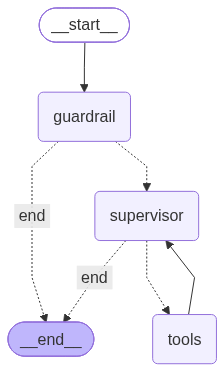

In [10]:
# ============ Visualise the LangGraph ============
# Requires: pip install grandalf  (or use mermaid / png)

try:
    from IPython.display import Image, display
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Graph visualisation not available:", e)
    print(graph.get_graph().draw_mermaid())

# Player Comparison


# Experiment: Player Comparison


In [11]:
comparison_salah_haaland = compare_players(PLAYER_ROWS, "Mohamed Salah", "Erling Haaland")
print(json.dumps(comparison_salah_haaland, ensure_ascii=False, indent=2))


{
  "status": "ok",
  "players": [
    {
      "player": "Mohamed Salah",
      "team": "Liverpool",
      "goals": 29,
      "assists": 18,
      "minutes": 3371,
      "appearances": 38,
      "per_90": {
        "goals": 0.77,
        "assists": 0.48,
        "goals_assists": 1.25,
        "non_penalty_goals": 0.53,
        "non_penalty_goals_assists": 1.01
      }
    },
    {
      "player": "Erling Haaland",
      "team": "Manchester City",
      "goals": 22,
      "assists": 3,
      "minutes": 2736,
      "appearances": 31,
      "per_90": {
        "goals": 0.72,
        "assists": 0.1,
        "goals_assists": 0.82,
        "non_penalty_goals": 0.62,
        "non_penalty_goals_assists": 0.72
      }
    }
  ],
  "difference_player_a_minus_player_b": {
    "goals": 7,
    "assists": 15,
    "minutes": 635,
    "appearances": 7,
    "per_90": {
      "goals": 0.05,
      "assists": 0.38,
      "goals_assists": 0.43,
      "non_penalty_goals": -0.09,
      "non_penalty_goals_ass

# Experiment: Duplicate and Missing Players


In [12]:
duplicate_unresolved = compare_players(PLAYER_ROWS, "Carlos Alcaraz", "Erling Haaland")
duplicate_qualified = compare_players(PLAYER_ROWS, "Carlos Alcaraz", "Erling Haaland", team_a="Everton")
missing_player = compare_players(PLAYER_ROWS, "Not A Real Player", "Erling Haaland")
print(json.dumps({
    "duplicate_without_team": duplicate_unresolved,
    "duplicate_qualified": {"status": duplicate_qualified["status"], "player": duplicate_qualified.get("players", [{}])[0]},
    "missing_player": missing_player,
}, ensure_ascii=False, indent=2))


{
  "duplicate_without_team": {
    "status": "clarification_required",
    "players": [
      {
        "requested": "Carlos Alcaraz",
        "team": null,
        "status": "ambiguous",
        "candidates": [
          {
            "player": "Carlos Alcaraz",
            "team": "Southampton"
          },
          {
            "player": "Carlos Alcaraz",
            "team": "Everton"
          }
        ]
      }
    ]
  },
  "duplicate_qualified": {
    "status": "ok",
    "player": {
      "player": "Carlos Alcaraz",
      "team": "Everton",
      "goals": 2,
      "assists": 3,
      "minutes": 764,
      "appearances": 15,
      "per_90": {
        "goals": 0.24,
        "assists": 0.35,
        "goals_assists": 0.59,
        "non_penalty_goals": 0.24,
        "non_penalty_goals_assists": 0.59
      }
    }
  },
  "missing_player": {
    "status": "clarification_required",
    "players": [
      {
        "requested": "Not A Real Player",
        "team": null,
        "statu

# Experiment: Appearances and Per-90 Fields


In [13]:
salah_tool_row = json.loads(get_player_stats.invoke({"player_name": "Mohamed Salah", "limit": 1}))[0]
salah_csv_row = next(r for r in PLAYER_ROWS if r["Player"] == "Mohamed Salah")
print(json.dumps({
    "player": salah_tool_row["player"], "team": salah_tool_row["team"],
    "tool_appearances": salah_tool_row["appearances"],
    "Playing Time_MP": salah_csv_row["Playing Time_MP"],
    "Per 90 Minutes_Gls": salah_csv_row["Per 90 Minutes_Gls"],
    "Per 90 Minutes_Ast": salah_csv_row["Per 90 Minutes_Ast"],
}, ensure_ascii=False, indent=2))


{
  "player": "Mohamed Salah",
  "team": "Liverpool",
  "tool_appearances": 38,
  "Playing Time_MP": "38",
  "Per 90 Minutes_Gls": "0.77",
  "Per 90 Minutes_Ast": "0.48"
}


# Experiment: Zero-Minute Player


In [14]:
zero_minute_rows = [
    {"Player": "Zero Minutes", "Squad": "Test FC", "Playing Time_Min": "0", "Playing Time_MP": "0",
     "Performance_Gls": "0", "Performance_Ast": "0", "Per 90 Minutes_Gls": "0.00", "Per 90 Minutes_Ast": "0.00"},
    {"Player": "Other", "Squad": "Test FC", "Playing Time_Min": "90", "Playing Time_MP": "1",
     "Performance_Gls": "1", "Performance_Ast": "0", "Per 90 Minutes_Gls": "1.00", "Per 90 Minutes_Ast": "0.00"},
]
zero_minute_result = compare_players(zero_minute_rows, "Zero Minutes", "Other")
assert zero_minute_result["players"][0]["minutes"] == 0
assert zero_minute_result["players"][0]["per_90"]["goals"] is None
assert zero_minute_result["difference_player_a_minus_player_b"]["per_90"]["goals"] is None
print("PASS: zero minutes produce unavailable per-90 values, not estimates")


PASS: zero minutes produce unavailable per-90 values, not estimates


# Team Form


# Experiment: Latest Five Matches


In [15]:
arsenal_form = team_form(MATCH_REPORTS, "Arsenal")
print(json.dumps(arsenal_form, ensure_ascii=False, indent=2))


{
  "status": "ok",
  "data_period": {
    "start": "2024-08-18",
    "end": "2024-12-22"
  },
  "coverage_note": "Repository coverage is partial for the 2024/25 season; these are only the matches present in the available reports, which end on 2024-12-22. They are not current real-world results.",
  "teams": [
    {
      "team": "Arsenal",
      "matches_available": 16,
      "matches_in_form": 5,
      "most_recent_available_match_date": "2024-12-21",
      "matches": [
        {
          "date": "2024-12-21",
          "opponent": "Crystal Palace",
          "score": "5-1",
          "goals_for": 5,
          "goals_against": 1,
          "venue_status": "away",
          "result": "W"
        },
        {
          "date": "2024-12-14",
          "opponent": "Everton",
          "score": "0-0",
          "goals_for": 0,
          "goals_against": 0,
          "venue_status": "home",
          "result": "D"
        },
        {
          "date": "2024-12-08",
          "opponent": 

# Experiment: Home, Away, and Draw


In [16]:
def experiment_match(day, home, away, home_score, away_score):
    return {"date": f"2024-08-{day:02d}", "teams": {
        "home": {"name": home, "score": home_score},
        "away": {"name": away, "score": away_score}}, "venue": f"{home} ground"}

home_away_draw_fixtures = [
    experiment_match(1, "Arsenal", "Chelsea", 2, 1),
    experiment_match(8, "Chelsea", "Arsenal", 0, 1),
    experiment_match(15, "Arsenal", "Chelsea", 1, 1),
]
print(json.dumps(team_form(home_away_draw_fixtures, "Arsenal"), ensure_ascii=False, indent=2))


{
  "status": "ok",
  "data_period": {
    "start": "2024-08-01",
    "end": "2024-08-15"
  },
  "coverage_note": "Repository coverage is partial for the 2024/25 season; these are only the matches present in the available reports, which end on 2024-12-22. They are not current real-world results.",
  "teams": [
    {
      "team": "Arsenal",
      "matches_available": 3,
      "matches_in_form": 3,
      "most_recent_available_match_date": "2024-08-15",
      "matches": [
        {
          "date": "2024-08-15",
          "opponent": "Chelsea",
          "score": "1-1",
          "goals_for": 1,
          "goals_against": 1,
          "venue_status": "home",
          "result": "D"
        },
        {
          "date": "2024-08-08",
          "opponent": "Chelsea",
          "score": "1-0",
          "goals_for": 1,
          "goals_against": 0,
          "venue_status": "away",
          "result": "W"
        },
        {
          "date": "2024-08-01",
          "opponent": "Chelsea

# Experiment: Two-Team Form


In [17]:
arsenal_chelsea_form = team_form(MATCH_REPORTS, "Arsenal", "Chelsea")
print(json.dumps(arsenal_chelsea_form, ensure_ascii=False, indent=2))


{
  "status": "ok",
  "data_period": {
    "start": "2024-08-18",
    "end": "2024-12-22"
  },
  "coverage_note": "Repository coverage is partial for the 2024/25 season; these are only the matches present in the available reports, which end on 2024-12-22. They are not current real-world results.",
  "teams": [
    {
      "team": "Arsenal",
      "matches_available": 16,
      "matches_in_form": 5,
      "most_recent_available_match_date": "2024-12-21",
      "matches": [
        {
          "date": "2024-12-21",
          "opponent": "Crystal Palace",
          "score": "5-1",
          "goals_for": 5,
          "goals_against": 1,
          "venue_status": "away",
          "result": "W"
        },
        {
          "date": "2024-12-14",
          "opponent": "Everton",
          "score": "0-0",
          "goals_for": 0,
          "goals_against": 0,
          "venue_status": "home",
          "result": "D"
        },
        {
          "date": "2024-12-08",
          "opponent": 

# Experiment: Resolution and Short Histories


In [18]:
few_matches = team_form(home_away_draw_fixtures[:2], "Arsenal")
unknown_team = team_form(MATCH_REPORTS, "Barcelona")
ambiguous_fixtures = [
    experiment_match(1, "Manchester United", "Chelsea", 1, 0),
    experiment_match(2, "Sheffield United", "Arsenal", 1, 0),
]
ambiguous_team = team_form(ambiguous_fixtures, "United")
print(json.dumps({"fewer_than_five": few_matches["teams"][0],
                  "unknown_team": unknown_team, "ambiguous_team": ambiguous_team},
                 ensure_ascii=False, indent=2))


{
  "fewer_than_five": {
    "team": "Arsenal",
    "matches_available": 2,
    "matches_in_form": 2,
    "most_recent_available_match_date": "2024-08-08",
    "matches": [
      {
        "date": "2024-08-08",
        "opponent": "Chelsea",
        "score": "1-0",
        "goals_for": 1,
        "goals_against": 0,
        "venue_status": "away",
        "result": "W"
      },
      {
        "date": "2024-08-01",
        "opponent": "Chelsea",
        "score": "2-1",
        "goals_for": 2,
        "goals_against": 1,
        "venue_status": "home",
        "result": "W"
      }
    ],
    "summary": {
      "wins": 2,
      "draws": 0,
      "losses": 0,
      "goals_scored": 3,
      "goals_conceded": 1,
      "goal_difference": 2,
      "points": 6
    }
  },
  "unknown_team": {
    "status": "clarification_required",
    "data_period": {
      "start": "2024-08-18",
      "end": "2024-12-22"
    },
    "coverage_note": "Repository coverage is partial for the 2024/25 season; these

# Head-to-Head


# Experiment: Repository Head-to-Head


In [19]:
chelsea_arsenal_h2h = head_to_head(MATCH_REPORTS, "Chelsea", "Arsenal")
print(json.dumps(chelsea_arsenal_h2h, ensure_ascii=False, indent=2))


{
  "status": "ok",
  "team_a": "Chelsea",
  "team_b": "Arsenal",
  "matches": [
    {
      "date": "2024-11-10",
      "home_team": "Chelsea",
      "away_team": "Arsenal",
      "score": "1-1",
      "home_score": 1,
      "away_score": 1,
      "venue": "Stamford Bridge, London",
      "result_for_first_team": "D"
    }
  ],
  "summary_for_team_a": {
    "total_matches": 1,
    "wins": 0,
    "draws": 1,
    "losses": 0,
    "goals_scored": 1,
    "goals_conceded": 1
  },
  "history_note": "Head-to-head history is incomplete: this includes only meetings present in the repository's partial 2024/25 match reports, ending on 2024-12-22. It does not establish the complete earlier or later history between these teams.",
  "data_period": {
    "start": "2024-08-18",
    "end": "2024-12-22"
  },
  "coverage_note": "Repository coverage is partial for the 2024/25 season; these are only the matches present in the available reports, which end on 2024-12-22. They are not current real-world resu

# Experiment: Head-to-Head Orientation


In [20]:
arsenal_first_h2h = head_to_head(home_away_draw_fixtures, "Arsenal", "Chelsea")
chelsea_first_h2h = head_to_head(home_away_draw_fixtures, "Chelsea", "Arsenal")
print(json.dumps({"Arsenal_first": arsenal_first_h2h["summary_for_team_a"],
                  "Chelsea_first": chelsea_first_h2h["summary_for_team_a"],
                  "matches": arsenal_first_h2h["matches"]}, ensure_ascii=False, indent=2))


{
  "Arsenal_first": {
    "total_matches": 3,
    "wins": 2,
    "draws": 1,
    "losses": 0,
    "goals_scored": 4,
    "goals_conceded": 2
  },
  "Chelsea_first": {
    "total_matches": 3,
    "wins": 0,
    "draws": 1,
    "losses": 2,
    "goals_scored": 2,
    "goals_conceded": 4
  },
  "matches": [
    {
      "date": "2024-08-01",
      "home_team": "Arsenal",
      "away_team": "Chelsea",
      "score": "2-1",
      "home_score": 2,
      "away_score": 1,
      "venue": "Arsenal ground",
      "result_for_first_team": "W"
    },
    {
      "date": "2024-08-08",
      "home_team": "Chelsea",
      "away_team": "Arsenal",
      "score": "0-1",
      "home_score": 0,
      "away_score": 1,
      "venue": "Chelsea ground",
      "result_for_first_team": "W"
    },
    {
      "date": "2024-08-15",
      "home_team": "Arsenal",
      "away_team": "Chelsea",
      "score": "1-1",
      "home_score": 1,
      "away_score": 1,
      "venue": "Arsenal ground",
      "result_for_first_

# Experiment: Unknown Team


In [21]:
unknown_h2h = head_to_head(MATCH_REPORTS, "Barcelona", "Arsenal")
print(json.dumps(unknown_h2h, ensure_ascii=False, indent=2))


{
  "status": "clarification_required",
  "teams": [
    {
      "status": "clarification_required",
      "reason": "missing",
      "requested": "Barcelona",
      "candidates": []
    }
  ],
  "data_period": {
    "start": "2024-08-18",
    "end": "2024-12-22"
  },
  "coverage_note": "Repository coverage is partial for the 2024/25 season; these are only the matches present in the available reports, which end on 2024-12-22. They are not current real-world results."
}


# Scoring Milestones


# Experiment: Default Scope and Explicit History Limits


In [50]:
milestone_scope_examples = [
    "Who scored the first hat-trick?",
    "Who reached 10 goals first?",
    "who reatched 10 goles first",
]
for question in milestone_scope_examples:
    print(question, "=>", classify_question_scope(question), "|", query_scoring_milestone(MATCH_REPORTS, question))
all_time_hat_trick = query_scoring_milestone(MATCH_REPORTS, "Who scored the first hat-trick ever?")
print("Explicit all-time request =>", all_time_hat_trick)
assert normalize_football_question(milestone_scope_examples[2]) == "who reached 10 goals first"
assert all(classify_question_scope(q) == "in_scope" for q in milestone_scope_examples)
assert all("do you mean" not in query_scoring_milestone(MATCH_REPORTS, q).casefold() for q in milestone_scope_examples)
assert "can't verify" in all_time_hat_trick


Who scored the first hat-trick? => in_scope | Earliest hat-trick date in the available reports: 2024-08-24 - Erling Haaland (Manchester City). Supporting match: Erling Haaland: 2024-08-24, Matchweek 2, Manchester City 4-1 Ipswich Town. Data period: 2024-08-18 to 2024-12-22. Milestone totals use only individual player goal rows in the available 2024/25 match reports. Reports cover only part of the season through 2024-12-22; they do not establish Premier League all-time records or the complete season. The reports give player goals per match and match dates, not individual goal timestamps. A result is ordered by match date; the exact scoring order within a match or on the same date cannot be established.
Who reached 10 goals first? => in_scope | First recorded match date to reach 10 goals: 2024-09-22 - Erling Haaland (Manchester City, 9 to 10 goals). Supporting match: Erling Haaland: 2024-09-22, Matchweek 5, Manchester City 2-2 Arsenal; 1 goal in match. Data period: 2024-08-18 to 2024-12-

# Experiment: Default Player Statistics


In [52]:
top_goal_scorer = json.loads(get_player_stats(stat="goals", limit=1))[0]
clean_sheets_result = json.loads(get_player_stats(stat="clean_sheets"))
print("Top goals", query_player_leader(PLAYER_ROWS, "Who scored the most goals?"))
print("Top assists", query_player_leader(PLAYER_ROWS, "Which player had the most assists?"))
print("Most appearances", query_player_leader(PLAYER_ROWS, "Who had the most appearances?"))
print("Team goals", query_team_table_leader(TABLE_ROWS, "Which team scored the most goals?"))
print("Clean sheets", clean_sheets_result)
assert top_goal_scorer["player"] == "Mohamed Salah"
assert clean_sheets_result["status"] == "unsupported"


Top goals Most goals in the project's Premier League 2024/25 player statistics: Mohamed Salah (Liverpool) - 29 goals.
Top assists Most assists in the project's Premier League 2024/25 player statistics: Mohamed Salah (Liverpool) - 18 assists.
Most appearances Most appearances in the project's Premier League 2024/25 player statistics: Moisés Caicedo (Chelsea), Nathan Collins (Brentford), Mikkel Damsgaard (Brentford), Anthony Elanga (Nottingham Forest), Bruno Guimarães (Newcastle United), Dean Henderson (Crystal Palace), Alex Iwobi (Fulham), Raúl Jiménez (Fulham), Milos Kerkez (Bournemouth), Max Kilman (West Ham United), Bernd Leno (Fulham), Keane Lewis-Potter (Brentford), Bryan Mbeumo (Brentford), Jordan Pickford (Everton), David Raya (Arsenal), Mohamed Salah (Liverpool), Ismaila Sarr (Crystal Palace), Kevin Schade (Brentford), Matz Sels (Nottingham Forest), Leandro Trossard (Arsenal), Ollie Watkins (Aston Villa) - 38 appearances.
Team goals In the project's Premier League 2024/25 league

# Experiment: First Hat-Trick in Available Reports


In [54]:
first_hat_trick_result = first_hat_tricks(MATCH_REPORTS)
print(json.dumps(first_hat_trick_result, ensure_ascii=False, indent=2))
assert first_hat_trick_result["candidates"][0]["player"] == "Erling Haaland"
assert first_hat_trick_result["candidates"][0]["date"] == "2024-08-24"
assert "cannot be established" in first_hat_trick_result["precision_note"]


{
  "status": "ok",
  "milestone": "first_hat_trick",
  "candidates": [
    {
      "date": "2024-08-24",
      "matchweek": 2,
      "player": "Erling Haaland",
      "team": "Manchester City",
      "opponent": "Ipswich Town",
      "venue_status": "home",
      "goals_in_match": 3,
      "home_team": "Manchester City",
      "away_team": "Ipswich Town",
      "home_score": 4,
      "away_score": 1,
      "venue_time": "15:00"
    }
  ],
  "data_period": {
    "start": "2024-08-18",
    "end": "2024-12-22"
  },
  "coverage_note": "Repository coverage is partial for the 2024/25 season; these are only the matches present in the available reports, which end on 2024-12-22. They are not current real-world results.",
  "scope_note": "Milestone totals use only individual player goal rows in the available 2024/25 match reports. Reports cover only part of the season through 2024-12-22; they do not establish Premier League all-time records or the complete season.",
  "precision_note": "The rep

# Experiment: First to Ten Goals in Available Reports


In [56]:
first_ten_goals_result = first_to_goal_threshold(MATCH_REPORTS, 10)
print(json.dumps(first_ten_goals_result, ensure_ascii=False, indent=2))
print(query_scoring_milestone(MATCH_REPORTS, "Who reached 10 goals first this season?"))
assert first_ten_goals_result["candidates"][0]["player"] == "Erling Haaland"
assert first_ten_goals_result["candidates"][0]["date"] == "2024-09-22"
assert first_ten_goals_result["candidates"][0]["goal_total_before"] == 9


{
  "status": "ok",
  "milestone": "goal_threshold",
  "threshold": 10,
  "candidates": [
    {
      "player": "Erling Haaland",
      "team": "Manchester City",
      "date": "2024-09-22",
      "goal_total_before": 9,
      "goal_total_after": 10,
      "goals_in_matches_on_date": 1,
      "matches": [
        {
          "date": "2024-09-22",
          "matchweek": 5,
          "opponent": "Arsenal",
          "venue_status": "home",
          "goals_in_match": 1,
          "home_team": "Manchester City",
          "away_team": "Arsenal",
          "home_score": 2,
          "away_score": 2,
          "venue_time": "16:30"
        }
      ]
    }
  ],
  "data_period": {
    "start": "2024-08-18",
    "end": "2024-12-22"
  },
  "coverage_note": "Repository coverage is partial for the 2024/25 season; these are only the matches present in the available reports, which end on 2024-12-22. They are not current real-world results.",
  "scope_note": "Milestone totals use only individual pla

# Experiment: Existing ask Workflow and Unrelated Questions


In [ ]:
print(ask("Who reached 10 goals first this season?"))
print(ask("Who scored the most goals?"))
print(ask("What is the weather today?"))


# Notebook Regression Checks


In [22]:
# Assertions mirror the focused player and team-analysis tests.
assert comparison_salah_haaland["status"] == "ok"
assert comparison_salah_haaland["players"][0]["appearances"] == 38
assert comparison_salah_haaland["players"][0]["per_90"]["goals_assists"] == 1.25
assert comparison_salah_haaland["difference_player_a_minus_player_b"]["goals"] == 7
assert duplicate_unresolved["status"] == "clarification_required"
assert duplicate_qualified["players"][0]["team"] == "Everton"
assert missing_player["players"][0]["status"] == "missing"
assert arsenal_form["teams"][0]["matches_in_form"] == 5
assert few_matches["teams"][0]["matches_in_form"] == 2
assert unknown_team["status"] == ambiguous_team["status"] == "clarification_required"
assert arsenal_first_h2h["summary_for_team_a"]["wins"] == 2
assert chelsea_first_h2h["summary_for_team_a"]["losses"] == 2
assert unknown_h2h["status"] == "clarification_required"
assert DATA_VALIDATION["match_reports"] == 158
print("PASS: migrated player-comparison and team-analysis regression assertions")


PASS: migrated player-comparison and team-analysis regression assertions


# Integration Testing


# Experiment: Player Comparison via ask


In [23]:
print(ask("Compare Mohamed Salah and Erling Haaland for goals, assists, minutes, appearances, and per-90 statistics."))


## Mohamed Salah (Liverpool) vs Erling Haaland (Manchester City)

| Statistic | Player A | Player B | A - B |
|---|---:|---:|---:|
| Goals | 29 | 22 | 7 |
| Assists | 18 | 3 | 15 |
| Minutes | 3371 | 2736 | 635 |
| Appearances | 38 | 31 | 7 |
| Goals per 90 | 0.77 | 0.72 | 0.05 |
| Assists per 90 | 0.48 | 0.1 | 0.38 |
| G+A per 90 (Per 90 Minutes_G+A) | 1.25 | 0.82 | 0.43 |
| Non-penalty goals per 90 | 0.53 | 0.62 | -0.09 |
| Non-penalty G+A per 90 (Per 90 Minutes_G+A-PK) | 1.01 | 0.72 | 0.29 |


# Experiment: Team Form via ask


In [24]:
print(ask("What is Arsenal's form in the last five matches?"))


## Arsenal — latest five available matches

Matches available in reports: 16. Most recent available match: 2024-12-21.
- 2024-12-21: vs Crystal Palace (away) 5-1 — W
- 2024-12-14: vs Everton (home) 0-0 — D
- 2024-12-08: vs Fulham (away) 1-1 — D
- 2024-12-04: vs Manchester United (home) 2-0 — W
- 2024-11-30: vs West Ham United (away) 5-2 — W
- Record: 3 W, 2 D, 0 L; 13 goals for, 4 against; goal difference +9; 11 points.

Data period: 2024-08-18 to 2024-12-22.
Repository coverage is partial for the 2024/25 season; these are only the matches present in the available reports, which end on 2024-12-22. They are not current real-world results.


# Experiment: Head-to-Head via ask


In [25]:
print(ask("Show the head-to-head record between Chelsea and Arsenal."))


## Head-to-head: Chelsea vs Arsenal

- 2024-11-10: Chelsea 1-1 Arsenal — Stamford Bridge, London (D for Chelsea)

Record for Chelsea: 1 matches; 0 wins, 1 draws, 0 losses; 1 goals scored, 1 conceded.
Data period: 2024-08-18 to 2024-12-22.
Head-to-head history is incomplete: this includes only meetings present in the repository's partial 2024/25 match reports, ending on 2024-12-22. It does not establish the complete earlier or later history between these teams.


# Evaluation
